# 03 — MLP sobre as features por janela

Usa as entradas de `02_preprocessing.ipynb` (`data/processed/`, gerado por `python -m src.prepare_data`):
- **Entrada**: 99 features por janela de 4 s (passo 2 s): MFCC (mean, std, std Δ, std ΔΔ), 6 descritores espectrais,
  energia relativa em 5 bandas e periodicidade do envelope. z-score com média/desvio **só dos folds de treino** (`mlp_arrays`).
- **Modelo**: MLP 99 → 256 → 128 → 3 (BatchNorm, ReLU, dropout 0.3), treinado com o rótulo por gravação (`rec_label`).
- **Treino**: cross-entropy com pesos de classe (inverso da frequência), Adam, early stopping na loss de validação.
- **Uma previsão por paciente**: média das janelas por gravação → máximo entre gravações de P(Present) e P(Unknown)
  → regra hierárquica com limiares afinados na validação (`src/evaluate.py`).

Protocolo: 5 folds de validação cruzada nos pacientes de desenvolvimento. O teste (fold −1) só se usa na última secção.

O treino pode correr aqui (`TRAIN = True`) ou noutro servidor com `python -m src.mlp`, que grava em `results/mlp/`;
com `TRAIN = False` o notebook só lê esses resultados.

In [1]:
import sys; sys.path.insert(0, '..')
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.data import CLASSES
from src.datasets import load_processed
from src.evaluate import RESULTS_DIR, patient_scores, cv_report, tune_thresholds, predict_rule, confusion_df, save_oof, load_oof, summary
from src.metrics import report
pd.set_option('display.width', 140)
d = load_processed()

## Treino (validação cruzada, um modelo por fold)

In [2]:
from src.mlp import DEFAULT_CFG, cross_validate, save_runs, load_runs, predict_ensemble
NAME, TRAIN = 'mlp', False
cfg = dict(DEFAULT_CFG)

if TRAIN:
    dev, oof, runs = cross_validate(d, cfg)
    t_, _, r_ = cv_report(patient_scores(dev, oof))
    out = save_oof(NAME, dev.index, oof, summary(t_, r_) | {'cfg': cfg, 'thresholds': tune_thresholds(patient_scores(dev, oof))[0]})
    save_runs(runs, cfg, out)
    hist = {r['fold']: r['history'] for r in runs}
else:
    idx, oof = load_oof(NAME)
    dev = d.windows.loc[idx]
    hist = {int(p.stem.split('fold')[1]): pd.read_csv(p) for p in sorted((RESULTS_DIR / NAME).glob('history_fold*.csv'))}
    print(json.loads((RESULTS_DIR / NAME / 'cv_summary.json').read_text())['cfg'])
print(len(dev), 'janelas de validação (out-of-fold)')

{'hidden': [256, 128], 'dropout': 0.3, 'lr': 0.001, 'weight_decay': 0.0001, 'batch_size': 256, 'max_epochs': 100, 'patience': 10, 'weight_power': 1.0, 'label_col': 'rec_label', 'seed': 42}
25367 janelas de validação (out-of-fold)


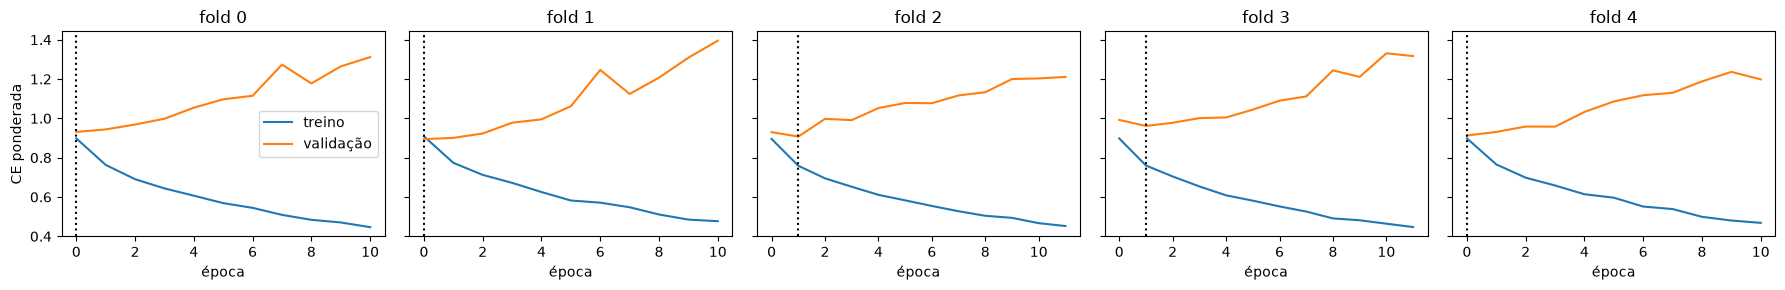

In [3]:
fig, axes = plt.subplots(1, len(hist), figsize=(3.6 * len(hist), 3), sharey=True)
for (k, h), ax in zip(hist.items(), np.atleast_1d(axes)):
    ax.plot(h.epoch, h.train_loss, label='treino'); ax.plot(h.epoch, h.val_loss, label='validação')
    ax.axvline(h.val_loss.idxmin(), ls=':', c='k'); ax.set(title=f'fold {k}', xlabel='época')
np.atleast_1d(axes)[0].set_ylabel('CE ponderada'); np.atleast_1d(axes)[0].legend(); plt.tight_layout()

## Avaliação por paciente
Para cada fold k os limiares (t_present, t_unknown) são escolhidos nas previsões out-of-fold dos outros 4 folds e aplicados ao fold k.

In [4]:
AGG = 'max'   # escolhido na comparação abaixo

pat = patient_scores(dev, oof, how=AGG)
table, pred, rep = cv_report(pat)
display(table.round(3))
print('WA (limiares afinados nos outros folds): %.3f ± %.3f | pooled %.3f' % (table['WA (tuned)'].mean(), table['WA (tuned)'].std(), rep['weighted_accuracy']))
print('recall:', {c: round(v, 3) for c, v in rep['recall'].items()})
confusion_df(rep)

,t_present,t_unknown,WA (t=0.5),WA (tuned)
fold,,,,
0,0.40,0.700,0.640,0.671
1,0.45,0.700,0.547,0.586
2,0.45,0.725,0.606,0.644
3,0.40,0.700,0.654,0.699
4,0.40,0.625,0.570,0.608


WA (limiares afinados nos outros folds): 0.642 ± 0.046 | pooled 0.642
recall: {'Present': np.float64(0.741), 'Unknown': np.float64(0.241), 'Absent': np.float64(0.631)}


,true Present,true Unknown,true Absent
pred Present,106,12,180
pred Unknown,6,13,25
pred Absent,31,29,351


### Agregação por paciente: `max` vs `max_present` vs `mean` (decisão na validação, 01_eda §5)

In [5]:
rows = []
for how in ['max', 'max_present', 'mean']:
    t, _, r = cv_report(patient_scores(dev, oof, how=how))
    rows.append({'agregação': how, 'WA média': t['WA (tuned)'].mean(), 'WA std': t['WA (tuned)'].std(), **{f'recall {c}': r['recall'][c] for c in CLASSES}})
pd.DataFrame(rows).set_index('agregação').round(3)

,WA média,WA std,recall Present,recall Unknown,recall Absent
agregação,,,,,
max,0.642,0.046,0.741,0.241,0.631
max_present,0.640,0.037,0.755,0.222,0.615
mean,0.644,0.023,0.615,0.426,0.745


Limiares finais para teste / dados escondidos: afinados em todas as previsões out-of-fold.

In [6]:
t_final, wa_oof = tune_thresholds(pat)
print('t_present = %.3f, t_unknown = %.3f (WA OOF %.3f, otimista)' % (*t_final, wa_oof))

t_present = 0.400, t_unknown = 0.700 (WA OOF 0.656, otimista)


## Teste — correr só uma vez, no fim
Ensemble dos 5 modelos dos folds (média das probabilidades por janela) + `t_final`. Nada daqui pode ser usado para mudar o modelo.

In [7]:
RUN_TEST = False
if RUN_TEST:
    runs = load_runs(RESULTS_DIR / NAME)
    te = (d.windows.fold == -1).to_numpy()
    pat_te = patient_scores(d.windows[te], predict_ensemble(runs, d.X_mlp[te]), how=AGG)
    r = report(pat_te.murmur, predict_rule(pat_te, *t_final))
    print('TESTE WA = %.3f' % r['weighted_accuracy'], {c: round(v, 3) for c, v in r['recall'].items()})
    display(confusion_df(r))